# Loading GALFORM Outputs

Low-level HDF5 reader. Use `read_snapshot_data` when you need direct access to the HDF5 file object, or `read_galaxy_arrays` (see the utils example) for a cleaner filtered interface.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import oh_mpl_paper

import galform_analysis
from galform_analysis import set_base_dir, get_base_dir, SimulationConfig, load_redshift_mapping

oh_mpl_paper.setconfig("k.wang")

# Configure the path to your GALFORM output directory once per session:
# set_base_dir('/cosma5/data/durham/<user>/Galform_Out/L800/model')
BASE_DIR = str(get_base_dir())
SIM = 'L800'

## Check which subvolumes completed

In [2]:
from galform_analysis.readers import get_completed_subvolumes
import os

iz_path = os.path.join(BASE_DIR, 'iz155')
completed = get_completed_subvolumes(iz_path)
print(f'Completed subvolumes in iz155: {len(completed)}')
print('First few ivols:', completed[:8])

Completed subvolumes in iz155: 1022
First few ivols: [0, 1, 2, 3, 4, 5, 6, 7]


## Read a single subvolume

In [3]:
from galform_analysis.readers import read_snapshot_data, close_snapshot

data = read_snapshot_data(iz_path, ivol=0)

print(f"Snapshot : {data['iz']},  ivol={data['ivol']},  z={data['z']:.4f}")
print(f"Galaxies : {len(data['mstar']):,}")
print(f"V_ivol   : {data['V_ivol']:.1f} (Mpc/h)^3")
print(f"Fields   : {[k for k in data if k not in ('file', 'group')]}")

close_snapshot(data)  # always close the HDF5 file handle

Snapshot : iz155,  ivol=0,  z=1.4955
Galaxies : 283,665
V_ivol   : 155626.1 (Mpc/h)^3
Fields   : ['iz', 'ivol', 'mstar', 'mhalo', 'sfr', 'Lg', 'Lr', 'z', 'V_ivol', 'V_total', 'n_subvolumes']


## Stellar-mass histogram

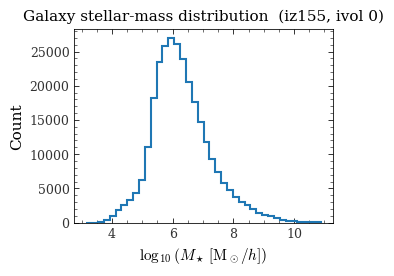

In [4]:
data = read_snapshot_data(iz_path, ivol=0)
mstar = data['mstar']
close_snapshot(data)

mstar_pos = mstar[mstar > 0]
fig, ax = plt.subplots()
ax.hist(np.log10(mstar_pos), bins=40, histtype='step', lw=1.5)
ax.set_xlabel(r'$\log_{10}(M_\star\,[\mathrm{M}_\odot/h])$')
ax.set_ylabel('Count')
ax.set_title('Galaxy stellar-mass distribution  (iz155, ivol 0)')
plt.show()